# Antennal grooming on MaleCNS: does Shiu et al. 2024 reproduce?

Issue #47. Shiu et al. 2024 (*Nature* 634: 210–219) ran a leaky integrate-and-fire model of the FlyWire (FAFB)
connectome and found that activating Johnston's organ neurons (JONs) drives the known antennal grooming circuit:
the brain interneurons **aBN1** and **aBN2** and the descending neurons **aDN1** and **aDN2** (Hampel et al. 2015).
They also predicted, and confirmed in flies, that JO-CE neurons drive aBN1 strongly while JO-F neurons do not.

flybrain runs the same kind of model on the male CNS (MaleCNS v1.0). This notebook asks whether the result holds there.

What it does:

1. Maps the paper's grooming neurons to MaleCNS cell types and reads their wiring from the weight matrix.
2. Injects voltage into the JO-C* / JO-E* neurons of one side at five strengths, across 32 noise seeds (flies), and
   ranks every other cell by its rate change against a paired no-stimulus run: top cell types, top descending neurons,
   and the grooming neurons.
3. Controls: the same stimulus on JO-A and JO-B (sound-tuned JONs), on JO-F (the paper's subtype prediction), on the
   other side, and on a brain whose postsynaptic partners are shuffled (each neuron keeps its output signs and degrees).
4. Says whether the result reproduces, partly reproduces or fails.

Run from a fresh install: `pip install flybrain matplotlib`, `flybrain download`, then run all cells.
Plots and CSVs are written to `notebooks/antennal_grooming/`. Simulated and wiring-only findings are labelled separately.

In [1]:
import csv, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

import flybrain
from flybrain import FlyBrain
from flybrain.data import ensure_data

# outputs go next to this notebook, whether it is run from notebooks/ or from the repo root
HERE = next(p for p in (Path.cwd(), Path.cwd() / "notebooks") if (p / "antennal_grooming.ipynb").exists())
OUT = HERE / "antennal_grooming"
OUT.mkdir(exist_ok=True)

BATCH = 16          # flies run side by side
REPEATS = 2         # batches per condition -> 32 flies (noise seeds) per condition
WARM = 10           # 0.2 s with no stimulus before each trial
STEPS = 50          # 1.0 s stimulus window (dt = 20 ms), as in the paper's 1,000 ms trials
STRENGTHS = [0.05, 0.1, 0.2, 0.4, 1.0]   # injected voltage per step; 1.0 makes every target fire every step (50 Hz)

DATA = ensure_data()
brain = FlyBrain(data=DATA, batch=BATCH, device="auto")
ct = brain.cell_type.astype(str); sd = brain.side.astype(str); sc = brain.superclass.astype(str)
print("flybrain", getattr(flybrain, "__version__", "?"), "| device", brain.device, "| neurons", brain.n, "| dt", brain.dt)

flybrain 0.1.1 | device cpu | neurons 166700 | dt 0.02


## The cells

Johnston's organ neuron groups, by MaleCNS cell type. The paper activated 147 JONs of the JO-C, JO-E, JO-F and JO-mz
classes in FAFB; the issue asks for JO-C* / JO-E*. MaleCNS side labels for JONs are uneven (for example 9 JO-CA2 on
the left and none on the right, and 95 `JO-unclear` on the right), so left and right groups differ in size.

In [2]:
def types_with(prefixes):
    return sorted(t for t in set(ct) if any(t.startswith(p) for p in prefixes))

JO = {
    "JO-CE": types_with(["JO-C", "JO-E"]),
    "JO-F":  types_with(["JO-F"]),
    "JO-A":  types_with(["JO-A"]),
    "JO-B":  types_with(["JO-B"]),
}
for g, ts in JO.items():
    print(f"{g:6} types={ts}")
    print(f"{'':6} cells L={len(brain.cells(ts, side='L'))} R={len(brain.cells(ts, side='R'))}")
print("JO-mz cells L/R:", len(brain.cells(['JO-mz'], side='L')), len(brain.cells(['JO-mz'], side='R')),
      "| JO-unclear L/R:", len(brain.cells(['JO-unclear'], side='L')), len(brain.cells(['JO-unclear'], side='R')))

JO-CE  types=[np.str_('JO-CA1'), np.str_('JO-CA2'), np.str_('JO-CL'), np.str_('JO-CM'), np.str_('JO-ED1'), np.str_('JO-ED2_a'), np.str_('JO-ED2_b'), np.str_('JO-ED2_c'), np.str_('JO-EV1'), np.str_('JO-EV2'), np.str_('JO-EV3'), np.str_('JO-EV4'), np.str_('JO-EV5'), np.str_('JO-EV6')]


       cells L=203 R=132
JO-F   types=[np.str_('JO-FD1'), np.str_('JO-FD2'), np.str_('JO-FV')]
       cells L=42 R=36
JO-A   types=[np.str_('JO-A'), np.str_('JO-A1'), np.str_('JO-A2'), np.str_('JO-A3'), np.str_('JO-A4')]
       cells L=18 R=32
JO-B   types=[np.str_('JO-B'), np.str_('JO-B1_a'), np.str_('JO-B1_b'), np.str_('JO-B1_c'), np.str_('JO-B2'), np.str_('JO-B3'), np.str_('JO-B4_a'), np.str_('JO-B4_b')]
       cells L=59 R=29
JO-mz cells L/R: 11 0 | JO-unclear L/R: 7 95


### Paper names → MaleCNS names

From the Virtual Fly Brain / FlyBase anatomy ontology synonyms (`name_in_male-cns`, Berg et al. 2025, and FlyWire names):

| paper | FBbt term | FlyWire | MaleCNS type used here |
|---|---|---|---|
| aBN1 | FBbt:00111645 | SAD093 | `SAD093` |
| aDN1 | FBbt:00111647 | DNg62 (DNfl008) | `DNg62` |
| aDN2 | FBbt:00111648 | DNge078 | `DNge078` |
| aBN2 | FBbt:00111646 | — | no MaleCNS name in the ontology; not mapped |

aBN2 (three LB23-hemilineage cells) has no cell-type synonym, so it is left out rather than guessed. `DNg12` is listed
too: Namiki et al. 2018 called it similar to aDN1, and Guo et al. 2022 tied it to head and front-leg grooming.

In [3]:
GROOM = {"aBN1 (SAD093)": "SAD093", "aDN1 (DNg62)": "DNg62", "aDN2 (DNge078)": "DNge078", "DNg12 (all)": None}
DNG12 = types_with(["DNg12_"])
def gcells(name, side):
    t = GROOM[name]
    return brain.cells(DNG12 if t is None else [t], side=side)
for g in GROOM:
    print(f"{g:16} L={gcells(g, 'L').tolist()}  R={gcells(g, 'R').tolist()}")

aBN1 (SAD093)    L=[131195]  R=[1604]
aDN1 (DNg62)     L=[3382]  R=[4753]
aDN2 (DNge078)   L=[4198]  R=[23786]
DNg12 (all)      L=[8593, 8606, 10536, 10911, 10999, 11057, 11421, 12645, 13224, 13727, 20137, 27454, 33079, 34205, 39895, 46813, 124535, 124572, 139588, 158632]  R=[6755, 7852, 8764, 9207, 9509, 9796, 10953, 11317, 11393, 12340, 13458, 13535, 14856, 23647, 24791, 31101, 33235, 125437, 135006]


## Wiring (no simulation)

Summed synaptic weight from each JON group onto each grooming neuron, and from aBN1 onto the aDNs.
Rows of the weight matrix are postsynaptic cells. For scale: the median nonzero weight is about 0.0024 and the
99th percentile about 0.064; the model multiplies weights by a gain of 3.

In [4]:
W = sparse.load_npz(DATA / "weights.npz").tocsr()     # rows = postsynaptic
print("nonzero weight percentiles 50/90/99:", np.round(np.percentile(np.abs(W.data), [50, 90, 99]), 4))
wrows = []
for g in ["aBN1 (SAD093)", "aDN1 (DNg62)", "aDN2 (DNge078)"]:
    for s in "LR":
        post = gcells(g, s)
        row = np.asarray(W[post].sum(axis=0)).ravel()
        r = dict(target=g, side=s)
        for jg, ts in JO.items():
            for ps in "LR":
                r[f"{jg}_{ps}"] = round(float(row[brain.cells(ts, side=ps)].sum()), 4)
        for ps in "LR":
            r[f"aBN1_{ps}"] = round(float(row[gcells('aBN1 (SAD093)', ps)].sum()), 4)
        wrows.append(r)
with open(OUT / "wiring.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(wrows[0])); w.writeheader(); w.writerows(wrows)
cols = list(wrows[0])
print("  ".join(f"{c:>14}" for c in cols))
for r in wrows:
    print("  ".join(f"{str(r[c]):>14}" for c in cols))

nonzero weight percentiles 50/90/99: [0.0024 0.0139 0.0642]


        target            side         JO-CE_L         JO-CE_R          JO-F_L          JO-F_R          JO-A_L          JO-A_R          JO-B_L          JO-B_R          aBN1_L          aBN1_R
 aBN1 (SAD093)               L          0.1734             0.0          0.0194          0.0005          0.0202             0.0          0.0027             0.0             0.0             0.0
 aBN1 (SAD093)               R          0.0009          0.0798             0.0           0.018             0.0             0.0             0.0             0.0             0.0             0.0
  aDN1 (DNg62)               L             0.0             0.0             0.0           0.001             0.0             0.0             0.0             0.0          0.0099          0.0534
  aDN1 (DNg62)               R             0.0             0.0          0.0003             0.0             0.0             0.0             0.0             0.0           0.044          0.0068
aDN2 (DNge078)               L             0.

## Trial runner

One trial = reset with a seed, 0.2 s of rest, then 1 s with extra voltage injected every step into the target cells.
Every neuron's spike count in the 1 s window gives its rate (Hz) in each fly. Each stimulus condition is paired with a
no-stimulus run on the same seeds, so `Δ rate = stimulated − baseline` is computed fly by fly.

In [5]:
def trial(b, target_idx, amount, seed):
    b.reset(seed)
    for _ in range(WARM):
        b.step()
    counts = np.zeros((b.n, BATCH), np.int32)
    inject = [(target_idx, amount)] if (target_idx is not None and amount > 0) else []
    for _ in range(STEPS):
        for k, f in enumerate(b.step(inject=inject)):
            counts[f, k] += 1
    return counts / (STEPS * b.dt)          # Hz, (n, flies)

def condition(b, target_idx, amount, seed0=0):
    return np.concatenate([trial(b, target_idx, amount, seed0 + r) for r in range(REPEATS)], axis=1)

t0 = time.time()
base = condition(brain, None, 0.0)
print(f"baseline: {base.shape[1]} flies, mean rate {base.mean():.2f} Hz  ({time.time()-t0:.0f} s)")
for g in GROOM:
    print(f"  {g:16} baseline L {base[gcells(g,'L')].mean():.2f} Hz, R {base[gcells(g,'R')].mean():.2f} Hz")

baseline: 32 flies, mean rate 3.40 Hz  (11 s)
  aBN1 (SAD093)    baseline L 0.12 Hz, R 0.41 Hz
  aDN1 (DNg62)     baseline L 0.78 Hz, R 1.69 Hz
  aDN2 (DNge078)   baseline L 3.25 Hz, R 6.12 Hz
  DNg12 (all)      baseline L 4.60 Hz, R 5.03 Hz


## Dose: JO-CE left at five strengths

In [6]:
def jo(group, side):
    return brain.cells(JO[group], side=side)

def groom_summary(rates, base, label):
    rows = []
    for g in GROOM:
        for s in "LR":
            idx = gcells(g, s)
            d = (rates[idx] - base[idx]).mean(axis=0)          # per fly, mean over the cells of the type
            rows.append(dict(condition=label, neuron=g, side=s, n_cells=len(idx),
                             rate_hz=float(rates[idx].mean()), base_hz=float(base[idx].mean()),
                             delta_hz=float(d.mean()), delta_sd=float(d.std(ddof=1)),
                             z=float(d.mean() / (d.std(ddof=1) / np.sqrt(len(d)) + 1e-9))))
    return rows

groom_rows, runs = [], {}
t0 = time.time()
for a in STRENGTHS:
    r = condition(brain, jo("JO-CE", "L"), a)
    runs[("JO-CE", "L", a)] = r
    groom_rows += groom_summary(r, base, f"JO-CE L @{a}")
print(f"{len(STRENGTHS)} strengths in {time.time()-t0:.0f} s")
for row in groom_rows:
    print(f"{row['condition']:14} {row['neuron']:16} {row['side']}  rate {row['rate_hz']:6.2f}  Δ {row['delta_hz']:+6.2f} ± {row['delta_sd']:5.2f} Hz  z={row['z']:6.1f}")

5 strengths in 49 s
JO-CE L @0.05  aBN1 (SAD093)    L  rate   1.19  Δ  +1.06 ±  0.67 Hz  z=   9.0
JO-CE L @0.05  aBN1 (SAD093)    R  rate   0.44  Δ  +0.03 ±  0.47 Hz  z=   0.4
JO-CE L @0.05  aDN1 (DNg62)     L  rate   0.81  Δ  +0.03 ±  0.18 Hz  z=   1.0
JO-CE L @0.05  aDN1 (DNg62)     R  rate   2.00  Δ  +0.31 ±  0.86 Hz  z=   2.1
JO-CE L @0.05  aDN2 (DNge078)   L  rate   3.31  Δ  +0.06 ±  0.88 Hz  z=   0.4
JO-CE L @0.05  aDN2 (DNge078)   R  rate   6.31  Δ  +0.19 ±  1.23 Hz  z=   0.9
JO-CE L @0.05  DNg12 (all)      L  rate   4.58  Δ  -0.02 ±  0.52 Hz  z=  -0.2
JO-CE L @0.05  DNg12 (all)      R  rate   5.07  Δ  +0.04 ±  0.72 Hz  z=   0.4
JO-CE L @0.1   aBN1 (SAD093)    L  rate   2.56  Δ  +2.44 ±  0.95 Hz  z=  14.5
JO-CE L @0.1   aBN1 (SAD093)    R  rate   0.50  Δ  +0.09 ±  0.59 Hz  z=   0.9
JO-CE L @0.1   aDN1 (DNg62)     L  rate   0.94  Δ  +0.16 ±  0.37 Hz  z=   2.4
JO-CE L @0.1   aDN1 (DNg62)     R  rate   2.31  Δ  +0.62 ±  1.07 Hz  z=   3.3
JO-CE L @0.1   aDN2 (DNge078)   L  rate   3.

## Which cells respond (JO-CE left, strength 1.0)

Per cell, Δ rate averaged over the 32 flies; then per cell type and side, the mean over its cells. Stimulated JONs and
all other `JO-*` cells are left out of the ranking.

In [7]:
def ranking(rates, base, exclude_jo=True, only=None, top=20):
    d = (rates - base).mean(axis=1)
    keep = np.ones(brain.n, bool)
    if exclude_jo:
        keep &= ~np.char.startswith(ct, "JO")
    if only is not None:
        keep &= only
    keys = {}
    for i in np.flatnonzero(keep):
        keys.setdefault((ct[i] or "(untyped)", sd[i]), []).append(i)
    rows = [dict(cell_type=k[0], side=k[1], n_cells=len(v), delta_hz=float(d[v].mean()), max_cell_hz=float(d[v].max()))
            for k, v in keys.items()]
    rows.sort(key=lambda r: -r["delta_hz"])
    return rows[:top]

top = ranking(runs[("JO-CE", "L", 1.0)], base)
dns = ranking(runs[("JO-CE", "L", 1.0)], base, only=(sc == "descending_neuron"), top=15)
for title, rows in [("top cell types", top), ("top descending neurons", dns)]:
    print(title)
    for k, r in enumerate(rows, 1):
        print(f"  {k:2}. {r['cell_type']:22} {r['side']}  n={r['n_cells']:2}  Δ {r['delta_hz']:+6.2f} Hz (max cell {r['max_cell_hz']:+.2f})")
with open(OUT / "top_types.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=["list"] + list(top[0])); w.writeheader()
    w.writerows([dict(list="all", **r) for r in top] + [dict(list="descending", **r) for r in dns])

d_all = (runs[("JO-CE", "L", 1.0)] - base).mean(axis=1)
nonjo = ~np.char.startswith(ct, "JO")
order = np.argsort(-np.where(nonjo, d_all, -np.inf))
rank_of = {i: k + 1 for k, i in enumerate(order[: int(nonjo.sum())])}
print(f"\nrank of each grooming neuron among {int(nonjo.sum())} non-JO cells (by Δ rate):")
for g in GROOM:
    for s in "LR":
        print(f"  {g:16} {s}: " + ", ".join(f"#{rank_of[i]} (Δ {d_all[i]:+.2f} Hz)" for i in gcells(g, s)))

top cell types
   1. CB3320                 L  n= 3  Δ +32.55 Hz (max cell +33.81)
   2. CB3912                 L  n= 1  Δ +28.44 Hz (max cell +28.44)
   3. CB2322                 L  n= 2  Δ +24.53 Hz (max cell +25.25)
   4. CB3275b                L  n= 1  Δ +23.06 Hz (max cell +23.06)
   5. CB2067                 L  n= 3  Δ +21.30 Hz (max cell +26.16)
   6. CB1394_b               L  n= 2  Δ +20.78 Hz (max cell +21.25)
   7. CB2558                 L  n= 7  Δ +20.57 Hz (max cell +29.25)
   8. CB0958a                R  n= 5  Δ +20.46 Hz (max cell +24.72)
   9. CB0404                 L  n= 1  Δ +20.12 Hz (max cell +20.12)
  10. CB2440                 L  n= 4  Δ +19.64 Hz (max cell +22.75)
  11. CB1038a                L  n= 1  Δ +19.59 Hz (max cell +19.59)
  12. CB0978                 L  n= 3  Δ +19.43 Hz (max cell +22.97)
  13. CB3746                 L  n= 2  Δ +19.00 Hz (max cell +19.97)
  14. CB1231_a               L  n= 1  Δ +18.94 Hz (max cell +18.94)
  15. CB3200                 L  n

## Controls

All at strengths 0.4 and 1.0, same seeds, each against its own paired baseline:

* **JO-A**, **JO-B** (left): sound / vibration-tuned JONs, not the displacement-tuned JO-CE.
* **JO-F** (left): the paper predicted JO-F would *not* drive aBN1 (Shiu et al. 2024, Fig. 5g), and found that in flies.
* **JO-CE right**: the other side.
* **Shuffled brain**: every postsynaptic cell keeps its own input weights, but the presynaptic partner of each synapse
  is drawn at random from all neurons (one fixed permutation of the matrix's column indices, seed 0). JO-CE left is then
  stimulated the same way.

In [8]:
CONTROL_STRENGTHS = [0.4, 1.0]
for g, s in [("JO-A", "L"), ("JO-B", "L"), ("JO-F", "L"), ("JO-CE", "R")]:
    for a in CONTROL_STRENGTHS:
        r = condition(brain, jo(g, s), a)
        runs[(g, s, a)] = r
        groom_rows += groom_summary(r, base, f"{g} {s} @{a}")

# shuffled control: every synapse keeps its presynaptic cell and weight (so each neuron keeps the sign of its
# outputs and its out-degree); postsynaptic partners are permuted across all synapses, so in-degrees are kept too.
# Duplicate pairs merge. The matrix is swapped in memory on a second FlyBrain (FlyBrain internals, as in reservoir.ipynb).
coo = W.tocoo()
Ws = sparse.csr_matrix((coo.data, (np.random.default_rng(0).permutation(coo.row), coo.col)), shape=W.shape)
Ws.sum_duplicates(); Ws.sort_indices()
del coo
sign_out = lambda M: (np.asarray((M.tocsc() > 0).sum(0)).ravel(), np.asarray((M.tocsc() < 0).sum(0)).ravel())
pos0, neg0 = sign_out(W); pos1, neg1 = sign_out(Ws)
print(f"shuffled: {Ws.nnz:,} synapse pairs (real {W.nnz:,}); out-degree changed for {np.sum(pos0+neg0 != pos1+neg1):,} cells (merged duplicates); "
      f"cells with mixed-sign outputs: real {np.sum((pos0>0)&(neg0>0)):,}, shuffled {np.sum((pos1>0)&(neg1>0)):,}")
in0, in1 = np.asarray(W.sum(1)).ravel(), np.asarray(Ws.sum(1)).ravel()
print(f"summed input weight per cell: real mean {in0.mean():.4f}, shuffled {in1.mean():.4f}; "
      f"correlation across cells {np.corrcoef(in0, in1)[0, 1]:.2f} (not preserved per cell)")

shuf = FlyBrain(data=DATA, batch=BATCH, device=brain.device)
if shuf.device == "cuda":
    from cupyx.scipy import sparse as cusparse
    shuf._W = cusparse.csr_matrix(Ws.astype(np.float32))
csc = Ws.astype(np.float32).tocsc()
shuf.indptr, shuf.indices, shuf.weights = csc.indptr, csc.indices, csc.data
del csc
base_shuf = condition(shuf, None, 0.0)
for a in CONTROL_STRENGTHS:
    r = condition(shuf, jo("JO-CE", "L"), a)
    runs[("shuffled JO-CE", "L", a)] = r
    groom_rows += groom_summary(r, base_shuf, f"shuffled JO-CE L @{a}")
del shuf, Ws
for g in GROOM:
    print(f"  {g:16} baseline real L {base[gcells(g,'L')].mean():.2f} / R {base[gcells(g,'R')].mean():.2f} Hz; shuffled L {base_shuf[gcells(g,'L')].mean():.2f} / R {base_shuf[gcells(g,'R')].mean():.2f} Hz")

with open(OUT / "grooming_neurons.csv", "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=list(groom_rows[0])); w.writeheader(); w.writerows(groom_rows)
for row in groom_rows:
    if "@0.4" in row["condition"] or "@1.0" in row["condition"]:
        print(f"{row['condition']:24} {row['neuron']:16} {row['side']}  Δ {row['delta_hz']:+6.2f} ± {row['delta_sd']:5.2f} Hz  z={row['z']:6.1f}")
top_shuf = ranking(runs[("shuffled JO-CE", "L", 1.0)], base_shuf, top=10)
print("\nshuffled brain, JO-CE L @1.0, top cell types:")
for k, r in enumerate(top_shuf, 1):
    print(f"  {k:2}. {r['cell_type']:22} {r['side']}  n={r['n_cells']:2}  Δ {r['delta_hz']:+6.2f} Hz")

shuffled: 25,495,133 synapse pairs (real 25,582,938); out-degree changed for 29,674 cells (merged duplicates); cells with mixed-sign outputs: real 0, shuffled 0
summed input weight per cell: real mean 0.1035, shuffled 0.1035; correlation across cells 0.12 (not preserved per cell)


  aBN1 (SAD093)    baseline real L 0.12 / R 0.41 Hz; shuffled L 1.91 / R 2.50 Hz
  aDN1 (DNg62)     baseline real L 0.78 / R 1.69 Hz; shuffled L 1.41 / R 0.94 Hz
  aDN2 (DNge078)   baseline real L 3.25 / R 6.12 Hz; shuffled L 0.62 / R 1.25 Hz
  DNg12 (all)      baseline real L 4.60 / R 5.03 Hz; shuffled L 0.77 / R 1.00 Hz
JO-CE L @0.4             aBN1 (SAD093)    L  Δ  +7.75 ±  0.57 Hz  z=  77.2
JO-CE L @0.4             aBN1 (SAD093)    R  Δ  +0.00 ±  0.57 Hz  z=   0.0
JO-CE L @0.4             aDN1 (DNg62)     L  Δ  +0.16 ±  0.51 Hz  z=   1.7
JO-CE L @0.4             aDN1 (DNg62)     R  Δ  +1.47 ±  1.19 Hz  z=   7.0
JO-CE L @0.4             aDN2 (DNge078)   L  Δ  +0.16 ±  0.95 Hz  z=   0.9
JO-CE L @0.4             aDN2 (DNge078)   R  Δ  +1.34 ±  1.18 Hz  z=   6.4
JO-CE L @0.4             DNg12 (all)      L  Δ  +0.40 ±  0.82 Hz  z=   2.7
JO-CE L @0.4             DNg12 (all)      R  Δ  +0.63 ±  0.90 Hz  z=   4.0
JO-CE L @1.0             aBN1 (SAD093)    L  Δ +12.81 ±  0.74 Hz  z=  98.2
J


shuffled brain, JO-CE L @1.0, top cell types:
   1. CT1                    R  n= 1  Δ +13.81 Hz
   2. CB0461                 L  n= 1  Δ +13.28 Hz
   3. LAL142                 R  n= 1  Δ +12.41 Hz
   4. AN06B046               L  n= 1  Δ +11.97 Hz
   5. LAL010                 L  n= 1  Δ +11.47 Hz
   6. IN04B001               L  n= 1  Δ +10.78 Hz
   7. AN_GNG_20              R  n= 1  Δ  +9.50 Hz
   8. Li37                   R  n= 1  Δ  +9.44 Hz
   9. AN06B042               L  n= 1  Δ  +9.28 Hz
  10. cM05                   R  n= 1  Δ  +9.22 Hz


## Plots

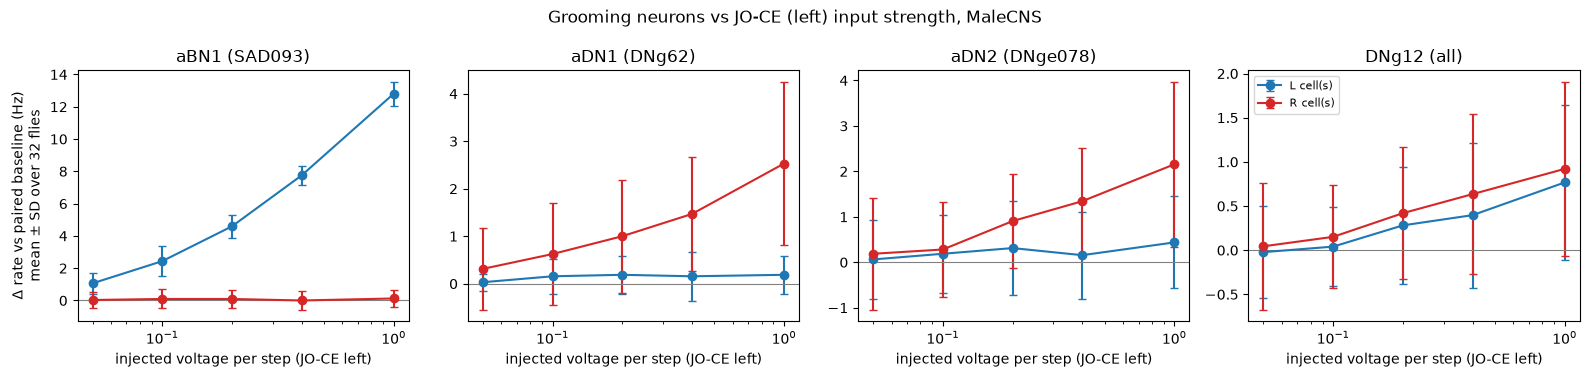

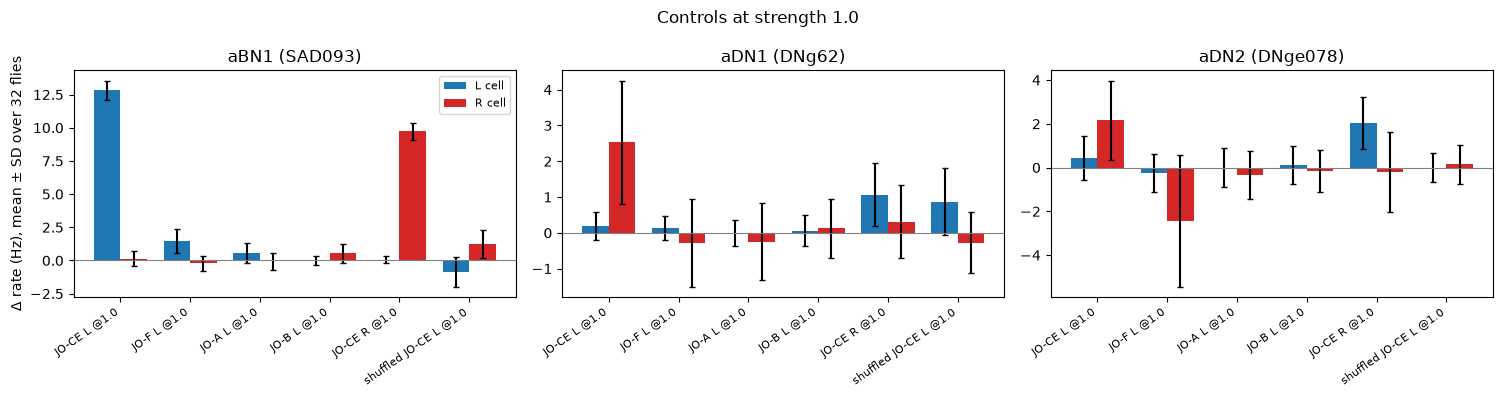

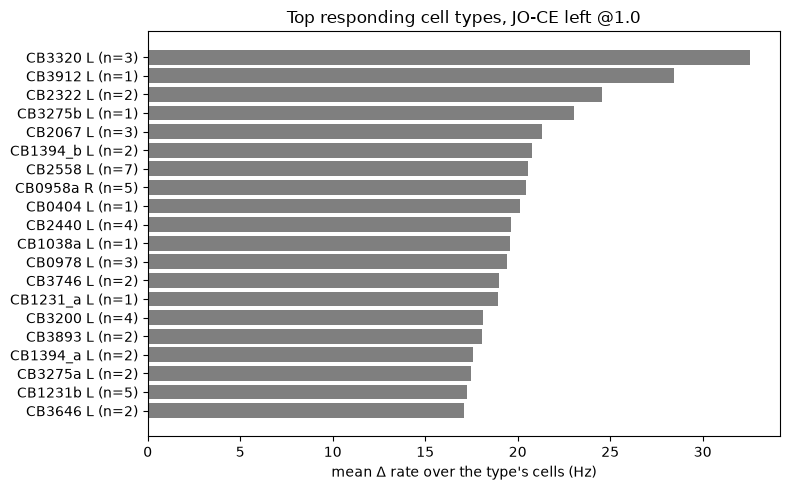

In [9]:
def pick(cond=None, g=None, s=None, prefix=None):
    return [r for r in groom_rows if (cond is None or r["condition"] == cond) and (g is None or r["neuron"] == g)
            and (s is None or r["side"] == s) and (prefix is None or r["condition"].startswith(prefix))]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, g in zip(axes, GROOM):
    for s, col in [("L", "tab:blue"), ("R", "tab:red")]:
        sub = pick(g=g, s=s, prefix="JO-CE L @")
        x = [float(r["condition"].split("@")[1]) for r in sub]
        ax.errorbar(x, [r["delta_hz"] for r in sub], yerr=[r["delta_sd"] for r in sub], marker="o", color=col, capsize=3, label=f"{s} cell(s)")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xscale("log"); ax.set_title(g); ax.set_xlabel("injected voltage per step (JO-CE left)")
axes[0].set_ylabel("Δ rate vs paired baseline (Hz)\nmean ± SD over 32 flies")
axes[-1].legend(fontsize=8)
fig.suptitle("Grooming neurons vs JO-CE (left) input strength, MaleCNS")
fig.tight_layout(); fig.savefig(OUT / "dose.png", dpi=110); plt.show()

conds = ["JO-CE L @1.0", "JO-F L @1.0", "JO-A L @1.0", "JO-B L @1.0", "JO-CE R @1.0", "shuffled JO-CE L @1.0"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, g in zip(axes, ["aBN1 (SAD093)", "aDN1 (DNg62)", "aDN2 (DNge078)"]):
    xs = np.arange(len(conds))
    for j, (s, col) in enumerate([("L", "tab:blue"), ("R", "tab:red")]):
        vals = [pick(c, g, s)[0] for c in conds]
        ax.bar(xs + (j - 0.5) * 0.38, [v["delta_hz"] for v in vals], 0.38, yerr=[v["delta_sd"] for v in vals],
               color=col, capsize=2, label=f"{s} cell")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(xs); ax.set_xticklabels(conds, rotation=35, ha="right", fontsize=8); ax.set_title(g)
axes[0].set_ylabel("Δ rate (Hz), mean ± SD over 32 flies"); axes[0].legend(fontsize=8)
fig.suptitle("Controls at strength 1.0")
fig.tight_layout(); fig.savefig(OUT / "controls.png", dpi=110); plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
lab = [f"{r['cell_type']} {r['side']} (n={r['n_cells']})" for r in top][::-1]
ax.barh(lab, [r["delta_hz"] for r in top][::-1], color="tab:gray")
ax.set_xlabel("mean Δ rate over the type's cells (Hz)"); ax.set_title("Top responding cell types, JO-CE left @1.0")
fig.tight_layout(); fig.savefig(OUT / "top_types.png", dpi=110); plt.show()

## Verdict

In [10]:
from types import SimpleNamespace
def get(cond, g, s):
    return SimpleNamespace(**pick(cond, g, s)[0])
abn = get("JO-CE L @1.0", "aBN1 (SAD093)", "L")
abn_f = get("JO-F L @1.0", "aBN1 (SAD093)", "L")
abn_sh = get("shuffled JO-CE L @1.0", "aBN1 (SAD093)", "L")
print(f"aBN1 L, JO-CE L @1.0: {abn.base_hz:.2f} -> {abn.rate_hz:.2f} Hz (Δ {abn.delta_hz:+.2f}, z {abn.z:.0f})")
print(f"aBN1 L, JO-F  L @1.0: Δ {abn_f.delta_hz:+.2f} Hz;  shuffled brain: Δ {abn_sh.delta_hz:+.2f} Hz")
for g in ["aDN1 (DNg62)", "aDN2 (DNge078)"]:
    for s in "LR":
        r = get("JO-CE L @1.0", g, s)
        print(f"{g} {s}, JO-CE L @1.0: Δ {r.delta_hz:+.2f} ± {r.delta_sd:.2f} Hz (z {r.z:.1f})")

aBN1 L, JO-CE L @1.0: 0.12 -> 12.94 Hz (Δ +12.81, z 98)
aBN1 L, JO-F  L @1.0: Δ +1.47 Hz;  shuffled brain: Δ -0.88 Hz
aDN1 (DNg62) L, JO-CE L @1.0: Δ +0.19 ± 0.40 Hz (z 2.7)
aDN1 (DNg62) R, JO-CE L @1.0: Δ +2.53 ± 1.72 Hz (z 8.3)
aDN2 (DNge078) L, JO-CE L @1.0: Δ +0.44 ± 1.01 Hz (z 2.4)
aDN2 (DNge078) R, JO-CE L @1.0: Δ +2.16 ± 1.82 Hz (z 6.7)


The written conclusion below was filled in from the outputs above of this run.

## Result: **partly reproduces**

All numbers are from this run (32 flies per condition, paired baselines, Δ = mean ± SD over flies).

**Reproduces: JO-CE → aBN1.**
* JO-CE left drives the left aBN1 (`SAD093`) from 0.12 Hz to 12.94 Hz at strength 1.0 (Δ +12.81 ± 0.74 Hz),
  with a smooth dose curve (Δ +1.06, +2.44, +4.59, +7.75, +12.81 Hz at 0.05 → 1.0). The right aBN1 stays at baseline (Δ +0.12 Hz).
* Mirror test: JO-CE right drives the right aBN1 (Δ +9.72 Hz at 1.0) and not the left one (+0.06 Hz). The right group has fewer
  labelled cells (132 vs 203).
* The paper's subtype prediction holds: JO-F left gives Δ +1.47 Hz on the left aBN1 against +12.81 Hz for JO-CE.
  JO-A (+0.56 Hz) and JO-B (+0.00 Hz) barely move it.
* The wiring explains it: 0.173 summed weight from JO-CE left onto the left aBN1, against 0.019 from JO-F and 0.020 from JO-A.
* A shuffled brain removes it: with postsynaptic partners permuted across all synapses (each neuron keeps the sign of its
  outputs and its in- and out-degree), the left aBN1 changes by −0.88 ± 1.10 Hz. This shuffle does not keep each cell's
  summed input weight (correlation 0.12 across cells), so baselines shift: aBN1 L 0.12 → 1.91 Hz, aDN2 R 6.12 → 1.25 Hz,
  `DNg12` L 4.60 → 0.77 Hz.

**Only weakly, and on the other side: aDN1 and aDN2.**
* JO-CE left raises the *right* aDN1 (`DNg62`, Δ +2.53 ± 1.72 Hz) and the *right* aDN2 (`DNge078`, +2.16 ± 1.82 Hz);
  the left ones barely change (+0.19 and +0.44 Hz). JO-CE right gives the mirror image (left aDN1 +1.06, left aDN2 +2.03 Hz).
* This matches the MaleCNS wiring: no direct JO-CE input onto either aDN, and aBN1 projects to the opposite-side aDNs
  (left aBN1 → right DNg62 0.044, right DNge078 0.060; ipsilateral 0.010 and 0).
* Among 166,028 non-JO cells, the left aBN1 ranks #103 by Δ rate; the right aDN1 and aDN2 rank #860 and #981.
  The paper found these four types among the top responders; here the aDNs move a few Hz on top of 1.7–6.1 Hz baselines.
* `DNg12` cells rise by +0.77 (left) and +0.92 Hz (right) on average. In the shuffled brain they rise by +0.32 and +0.12 Hz,
  about 40 % and 13 % of that, from a much lower baseline; so part of the left rise may not be specific, and the shuffle
  does not account for the right one.

**Not like the paper.**
* The strongest responders are other antennal-mechanosensory interneurons (`CB3320`, `CB3912`, `CB2322`, `CB2558`, …, +17 to +33 Hz),
  and the top descending neurons are `DNge016`, `DNg29`, `DNge091`, `DNg05_a`, `DNg07`, `DNg08` (+10 to +14 Hz), not the aDNs.
* JO-F left *lowers* the right aDN2 (Δ −2.44 ± 3.00 Hz at 1.0). In FAFB only JO-F neurons connect to aDN2 (Eichler et al., eLife 2025, Fig. 13F);
  in MaleCNS the summed JO-F weight onto either aDN2 is ≤ 0.007.
* aBN2 is not mapped to a MaleCNS type, so it is not tested.

So on MaleCNS the model keeps the first step of the circuit (JO-CE → aBN1, subtype-specific, side-specific, gone in a
shuffled brain), but aDN1 and aDN2 respond only weakly and contralaterally, and they are not among the top responders as in the paper.



## What the model leaves out

* **Input is voltage injection**, not antennal displacement or a Poisson spike train at a set rate as in the paper.
  At 20 ms steps a neuron fires at most 50 Hz, so the paper's 20–220 Hz JON rates cannot be matched; strength 1.0 here
  makes every target fire every step.
* **No silencing screen.** The paper also silenced each of the top 300 cells to find which are needed for aDN1; that is not done here.
* **aBN2 is not mapped** to a MaleCNS type, so it is not tested.
* **Side labels of MaleCNS JONs are uneven**, so left and right JON groups differ in size, and "the other side" is not a mirror image.
* **One wiring diagram** (seeds change only noise), fixed hand-calibrated parameters (nothing tuned here),
  no gap junctions beyond the chemical-synapse weights, no VNC or leg motor output, so "grooming" is read only from brain cells.
* The model's `sensory_input=True` default keeps synapses onto sensory cells, as in the original flybrain model.